# Phase 1: Supervised Learning — Customer Churn

## 1. Model Selection & Rationale

### 1.1 Problem Type and Dataset Summary
We are predicting whether a customer will churn. This is a binary classification task (`churn_flag`: 1 = churned, 0 = retained).

The dataset has 100,000 rows and 18 columns. We removed `customer_id` because it is only an identifier. We also removed `churn_risk` because it is built from the target. High always means churned and Low always means retained, so keeping it would leak the answer. That leaves 15 predictors: 10 numeric and 5 categorical.

Part A found no missing values. The classes are fairly balanced: 46.22% churned and 53.78% retained.


### 1.2 Logistic Regression


We chose Logistic Regression as our baseline model because it is simple, interpretable, and suitable for binary classification. It estimates the probability that a customer will churn.

Our Part A analysis supports this choice. The dataset contains 100,000 records, and the classes are fairly balanced, making it suitable for training and evaluating the model.

Logistic Regression assumes a linear relationship between features and the log-odds of churn. Therefore, it may not capture complex nonlinear patterns and feature interactions.

During Part A preprocessing, categorical features were converted using One-Hot Encoding, and numerical features were standardized using StandardScaler. This increased the number of input features from 15 to 30. We used the processed datasets for the baseline model and preprocessing pipelines during cross-validation to prevent data leakage.


### 1.3 Random Forest Classifier
We chose Random Forest to test whether a more flexible model does better. It can learn non-linear patterns and feature interactions, and it works well with a mix of numeric and categorical features. It does not need scaling and is not sensitive to skewed features.

It also gives feature importance scores, which helps us see which factors drive churn.

The trade-off is that it is harder to explain than Logistic Regression and slower to train.

### 1.4 Why This Pair
Logistic Regression is the simple, interpretable baseline. Random Forest is the flexible model. We will compare them on the same data split with the same metrics. This will show whether the extra complexity is worth it for this problem.

## 2. Implementation & Training Code

In [1]:
import pandas as pd

# Load the processed training and testing datasets from Part A
train = pd.read_csv("Dataset/Processed/train_processed.csv")
test = pd.read_csv("Dataset/Processed/test_processed.csv")

# Display dataset dimensions
print("Training data:", train.shape)
print("Testing data:", test.shape)

# Preview the training data
train.head()

Training data: (80000, 31)
Testing data: (20000, 31)


,categorical__age_group_18-24,categorical__age_group_25-34,categorical__age_group_35-44,categorical__age_group_45-54,categorical__age_group_55+,categorical__gender_Female,categorical__gender_Male,categorical__gender_Other,categorical__region_Central,categorical__region_East,...,numerical__avg_order_value,numerical__total_spent,numerical__recency_days,numerical__website_visits,numerical__discount_usage_rate,numerical__email_open_rate,numerical__cart_abandonment_rate,numerical__loyalty_score,numerical__engagement_score,churn_flag
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,-0.761699,-0.606332,-1.584302,-0.565563,-0.396897,0.471760,-0.266327,-0.058059,0.527209,0
1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,-0.638620,-0.234016,-1.422761,-0.005819,0.155764,-0.547079,-1.480694,1.135398,0.616482,0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,-1.317743,-0.507178,-0.444010,-0.234805,0.432095,1.327584,-0.353068,-1.713498,1.211637,0
3,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,-0.426651,-0.431940,0.173648,-0.412905,0.938701,0.757035,0.297486,-0.866529,0.348663,1
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,-1.622068,-0.661917,-0.634059,-0.654613,-0.489007,1.694366,0.470966,-1.559504,0.914059,0


In [2]:
# Separate features and target

X_train = train.drop(columns=["churn_flag"])
y_train = train["churn_flag"]

X_test = test.drop(columns=["churn_flag"])
y_test = test["churn_flag"]

# Display the dimensions
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (80000, 30)
y_train: (80000,)
X_test: (20000, 30)
y_test: (20000,)


In [3]:
print("Features used for training:")
print(X_train.columns.tolist())

Features used for training:
['categorical__age_group_18-24', 'categorical__age_group_25-34', 'categorical__age_group_35-44', 'categorical__age_group_45-54', 'categorical__age_group_55+', 'categorical__gender_Female', 'categorical__gender_Male', 'categorical__gender_Other', 'categorical__region_Central', 'categorical__region_East', 'categorical__region_North', 'categorical__region_South', 'categorical__region_West', 'categorical__customer_segment_Loyal', 'categorical__customer_segment_New', 'categorical__customer_segment_Returning', 'categorical__customer_segment_VIP', 'categorical__preferred_channel_In-Store', 'categorical__preferred_channel_Mobile App', 'categorical__preferred_channel_Online', 'numerical__purchase_frequency', 'numerical__avg_order_value', 'numerical__total_spent', 'numerical__recency_days', 'numerical__website_visits', 'numerical__discount_usage_rate', 'numerical__email_open_rate', 'numerical__cart_abandonment_rate', 'numerical__loyalty_score', 'numerical__engagement_

### 2.1 Logistic Regression – Training and Baseline Evaluation

In [ ]:
from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression model تحسين اجابة الموديل
lr_model = LogisticRegression(max_iter=1000)

# Train the model using processed training data  دربته باستخدام ال 30 فيتشر و الاجابه لن موديل ترين
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Predict customer churn using the test data هنا للتيست توقع
y_pred = lr_model.predict(X_test)# عطيته بيانات 20 بدون الاجابه

# Display the first 10 predictions
print("Predicted:", y_pred[:10])# الي هو توقعهم
print("Actual:   ", y_test.iloc[:10].values)# الاجابات الصحيحيه في تيتسنق

Predicted: [1 0 0 0 0 1 1 1 0 0]
Actual:    [1 0 0 0 0 1 1 1 0 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,# يقيس  نسبه التةقع بشكل عام الي بيطلعون او بيتسمرون صحيحه ام لا 
    precision_score,#نركز على دقه الكستوميز الي صدق توقع الموديل انهم بيطلعون
    recall_score,# هنا صدق الي طلعو فعلا  هل توقع ام لا 
    f1_score,# هنا يشوف توقعه مع الي طلعو فعلا
    roc_auc_score# ال طلعو وال مستمرين
)

# Predict churn probabilities
y_prob = lr_model.predict_proba(X_test)[:, 1]# هنا المودل المدرب بيتوقع  20 الف   بعدين بس بياخذ الي طلعو 1 مغادرين ويخزنه

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)# بيقارن 20 المتوقع مع الاجابه الحقيقه
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

# Display results
print("Logistic Regression - Baseline Results")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Logistic Regression - Baseline Results
Accuracy:  0.9459
Precision: 0.9419
Recall:    0.9410
F1-score:  0.9415
ROC-AUC:   0.9904


### 2.2 Random Forest – Training and Baseline Evaluation

In [7]:
#Model 2 - Random Forest
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

#Create preprocessing for random forest


#Create Random Forest Pipeline
rf_pipeline = Pipeline(
    steps=[
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=1
        ))
    ]
)

#Train Random Forest model
rf_pipeline.fit(X_train,y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [8]:
#Model 2 - Random Forest

#Predict customer churn
rf_y_pred = rf_pipeline.predict(X_test)

#Display the first 15 predictions
print("Predicted:",rf_y_pred[:15])
print("Actual:",y_test.iloc[:15].values)

Predicted: [0 1 0 0 0 1 1 1 0 0 1 0 0 0 0]
Actual: [1 0 0 0 0 1 1 1 0 0 1 0 0 0 0]


In [9]:
#Model 2 - Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Get predicted churn probabilities
rf_y_prob = rf_pipeline.predict_proba(X_test)[:, 1]

# Calculate metrics
rf_accuracy = accuracy_score(y_test, rf_y_pred)
rf_precision = precision_score(y_test, rf_y_pred)
rf_recall = recall_score(y_test, rf_y_pred)
rf_f1 = f1_score(y_test, rf_y_pred)
rf_roc_auc = roc_auc_score(y_test, rf_y_prob)

# Display results
print("Random Forest - Baseline Results")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_roc_auc, 4))

Random Forest - Baseline Results
Accuracy: 0.9421
Precision: 0.9389
Recall: 0.9355
F1-score: 0.9372
ROC-AUC: 0.988


# 3. Hyperparameter Tuning Process & Results

### 3.1 Logistic Regression – Hyperparameter Tuning

In [ ]:
import pandas as pd
#  وهو مفيد لتحسين الاداء:هنا رجعنا جربنا اعدادات مختلفه وبندرب الموديل على 64 الف وليس 80 عشان ماصيصير داتا ليكج
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler# نوحد المقايس الرقميه بلس نحول اي شي  كتابه الى اقام 
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Load training data before preprocessing
lr_train_selected = pd.read_csv(
    "Dataset/Processed/train_selected.csv"
)

# Separate features and target
lr_X_train = lr_train_selected.drop(columns=["churn_flag"])# كل 15
lr_y_train = lr_train_selected["churn_flag"] # الانسر

# Identify numerical and categorical features
lr_numerical_features = lr_X_train.select_dtypes(
    include=["number"]
).columns.tolist()

lr_categorical_features = lr_X_train.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

# Define preprocessing steps
lr_preprocessing_cv = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), lr_numerical_features),# للاعمده الرقميه 
        ("cat", OneHotEncoder(handle_unknown="ignore"),# للتحويل من نصوص لرقم
         lr_categorical_features)
    ]
)
# هنا  سوينا البايب لاين عشان يحافظ انه يمشي على شكل ستيبس بكل  جوله 
# Create Logistic Regression Pipeline
lr_cv_pipeline = Pipeline(
    steps=[
        ("preprocessing", lr_preprocessing_cv),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

# Define hyperparameter values
param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__solver": ["lbfgs", "liblinear"]
}

# Define 5-Fold Cross-Validation
cv = StratifiedKFold(
    n_splits=5,# نقسم 80 الف على خمسه
    shuffle=True,# نخلط ترتيب الكوستمرز 
    random_state=42
)

# Perform Hyperparameter Tuning
grid_search = GridSearchCV(
    estimator=lr_cv_pipeline,
    param_grid=param_grid,# الاعدادات  ال 8 الي بنجربها 
    scoring="f1",# هذا مقياس الي بيحدد ايهم احسن من 8
    cv=cv,#  بنجرب 8 لكل جوله40 
    n_jobs=-1
)

# Train and find the best parameters
grid_search.fit(lr_X_train, lr_y_train)

# Display the results
print("Best Parameters:", grid_search.best_params_)
print("Best CV F1-score:", round(grid_search.best_score_, 4))

Best Parameters: {'model__C': 0.01, 'model__solver': 'lbfgs'}
Best CV F1-score: 0.9395


In [11]:
# Model 2 - Random Forest
# 5-Fold Cross-Validation

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold


############# importing selected data and preparing the pipeline #############


# Load selected training data before preprocessing (to prevent data leakage)
rf_train_selected = pd.read_csv(
    "Dataset/Processed/train_selected.csv"
)

# Separate features and target
rf_X_train = rf_train_selected.drop(columns=["churn_flag"])
rf_y_train = rf_train_selected["churn_flag"]

# Identify feature types
rf_numerical_features = rf_X_train.select_dtypes(
    include=["number"]
).columns.tolist()

rf_categorical_features = rf_X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Preprocessing inside the Pipeline
rf_preprocessing_cv = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), rf_numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         rf_categorical_features)
    ]
)

# Random Forest Pipeline for Cross-Validation
rf_cv_pipeline = Pipeline(
    steps=[
        ("preprocessing", rf_preprocessing_cv),
        ("model", RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ))
    ]
)

###################################################################


# Hyperparameter grid
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20, None],
    "model__min_samples_split": [2, 5]
}

# 5-Fold Cross-Validation
rf_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid Search
rf_grid_search = GridSearchCV(
    estimator=rf_cv_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=rf_cv,
    n_jobs=-1,
    verbose=1
)

# Run tuning
rf_grid_search.fit(rf_X_train, rf_y_train)

# Display results
print("Best Parameters:", rf_grid_search.best_params_)
print("Best CV F1-score:", round(rf_grid_search.best_score_, 4))


Fitting 5 folds for each of 12 candidates, totalling 60 fits


C:\Users\albrh\AppData\Local\Temp\ipykernel_41304\4130104666.py:30: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  rf_categorical_features = rf_X_train.select_dtypes(


Best Parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV F1-score: 0.9347


### 3.3 Hyperparameter Tuning Discussion

F1-score was selected as the evaluation metric for hyperparameter tuning because it balances precision and recall. This is important in customer churn prediction, where both identifying customers at risk of leaving and reducing false positive predictions are valuable.

#### Logistic Regression

Hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation. Preprocessing was included within a Pipeline to prevent data leakage between validation folds.

The best parameters were C = 0.01 and solver = lbfgs, achieving a mean cross-validation F1-score of 0.9395.

#### Random Forest

Hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation. Preprocessing was included within a Pipeline to prevent data leakage between validation folds.

The best parameters were n_estimators = 200, max_depth = None, and min_samples_split = 2, achieving a mean cross-validation F1-score of 0.9347.

These parameters were selected based on the highest mean F1-score across the five validation folds.

## 4. Evaluation Metrics & Visualizations

In [ ]:
# Model 1 - Logistic Regression
# Tuned Model Evaluation

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Load selected test data before preprocessing
lr_test_selected = pd.read_csv(
    "Dataset/Processed/test_selected.csv"
)

# Separate features and target
lr_X_test = lr_test_selected.drop(columns=["churn_flag"])# العشرين الف بدون الاجابات
lr_y_test = lr_test_selected["churn_flag"]# الاجابات

# Get the best tuned Logistic Regression model
best_lr_model = grid_search.best_estimator_# المودل الي فاز قبل شوي جب معلوماته

# Make predictions
y_pred_tuned = best_lr_model.predict(lr_X_test)#توقع لل 20 الف 0و1 بيطلعون ولا لا
y_prob_tuned = best_lr_model.predict_proba(lr_X_test)[:, 1]# خذ الي  احتمال يغادرون

# Calculate evaluation metrics
tuned_accuracy = accuracy_score(lr_y_test, y_pred_tuned)# مقارنه بين توقع و الحقيقه
tuned_precision = precision_score(lr_y_test, y_pred_tuned)
tuned_recall = recall_score(lr_y_test, y_pred_tuned)
tuned_f1 = f1_score(lr_y_test, y_pred_tuned)
tuned_roc_auc = roc_auc_score(lr_y_test, y_prob_tuned)

# Display results
print("Logistic Regression - Tuned Results")
print(f"Accuracy:  {tuned_accuracy:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall:    {tuned_recall:.4f}")
print(f"F1-score:  {tuned_f1:.4f}")
print(f"ROC-AUC:   {tuned_roc_auc:.4f}")

Logistic Regression - Tuned Results
Accuracy:  0.9455
Precision: 0.9418
Recall:    0.9401
F1-score:  0.9409
ROC-AUC:   0.9904


### Logistic Regression - Baseline vs Tuned Comparison

The baseline Logistic Regression model achieved slightly better performance than the tuned model.

Accuracy decreased from 0.9459 to 0.9455, precision from 0.9419 to 0.9418, recall from 0.9410 to 0.9401, and F1-score from 0.9415 to 0.9409.

ROC-AUC remained approximately unchanged at 0.9904.

Overall, hyperparameter tuning did not improve Logistic Regression's performance on the test set. However, the differences were very small, indicating that both configurations performed similarly.



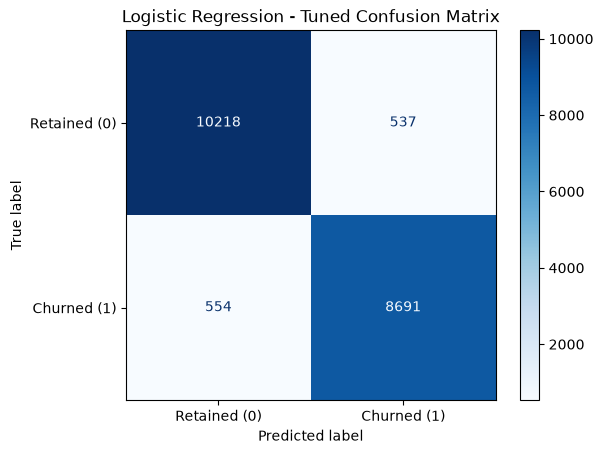

In [13]:
# Model 1 - Logistic Regression

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion Matrix for Tuned Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    lr_y_test,
    y_pred_tuned,
    display_labels=["Retained (0)", "Churned (1)"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Tuned Confusion Matrix")
plt.show()

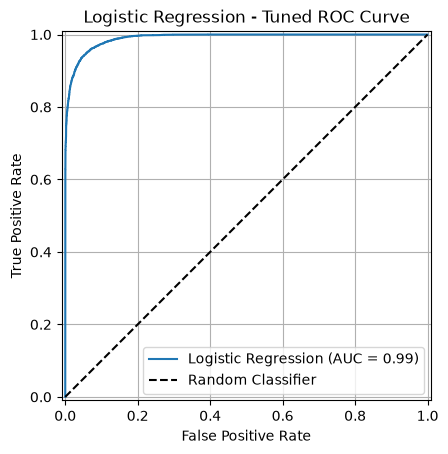

In [14]:
# Model 1 - Logistic Regression

import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Plot ROC Curve for Tuned Logistic Regression
RocCurveDisplay.from_predictions(
    lr_y_test,
    y_prob_tuned,
    name="Logistic Regression"
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("Logistic Regression - Tuned ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
#Model 2 - Random Forest

# Load selected test data before preprocessing
rf_test_selected = pd.read_csv(
    "Dataset/Processed/test_selected.csv"
)

# Separate features and target
rf_X_test = rf_test_selected.drop(columns=["churn_flag"])
rf_y_test = rf_test_selected["churn_flag"]

# Get the best tuned Random Forest model
rf_tuned_model = rf_grid_search.best_estimator_

# Make predictions
rf_tuned_pred = rf_tuned_model.predict(rf_X_test)
rf_tuned_prob = rf_tuned_model.predict_proba(rf_X_test)[:, 1]

# Calculate metrics
rf_tuned_accuracy = accuracy_score(rf_y_test, rf_tuned_pred)
rf_tuned_precision = precision_score(rf_y_test, rf_tuned_pred)
rf_tuned_recall = recall_score(rf_y_test, rf_tuned_pred)
rf_tuned_f1 = f1_score(rf_y_test, rf_tuned_pred)
rf_tuned_roc_auc = roc_auc_score(rf_y_test, rf_tuned_prob)

# Display results
print("Random Forest - Tuned Results")
print("Accuracy:", round(rf_tuned_accuracy, 4))
print("Precision:", round(rf_tuned_precision, 4))
print("Recall:", round(rf_tuned_recall, 4))
print("F1-score:", round(rf_tuned_f1, 4))
print("ROC-AUC:", round(rf_tuned_roc_auc, 4))


Random Forest - Tuned Results
Accuracy: 0.9424
Precision: 0.9387
Recall: 0.9365
F1-score: 0.9376
ROC-AUC: 0.9882


### Random Forest - Baseline vs Tuned Comparison

The tuned Random Forest model achieved slightly better performance than the baseline model in four out of five evaluation metrics.

Accuracy increased from 0.9421 to 0.9424, recall from 0.9355 to 0.9365, F1-score from 0.9372 to 0.9376, and ROC-AUC from 0.9880 to 0.9882.

However, precision decreased slightly from 0.9389 to 0.9387.

Overall, hyperparameter tuning was associated with a small improvement in performance, particularly in recall, which is important for identifying customers at risk of churn.

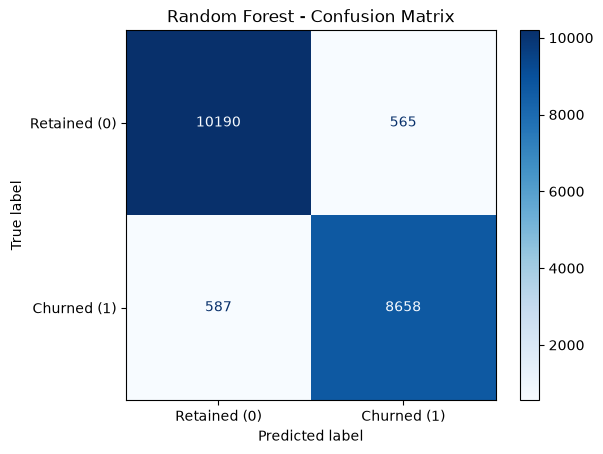

In [16]:
#Model 2 - Random Forest

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion Matrix for Tuned Random Forest
ConfusionMatrixDisplay.from_predictions(
    rf_y_test,
    rf_tuned_pred,
    display_labels=["Retained (0)", "Churned (1)"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

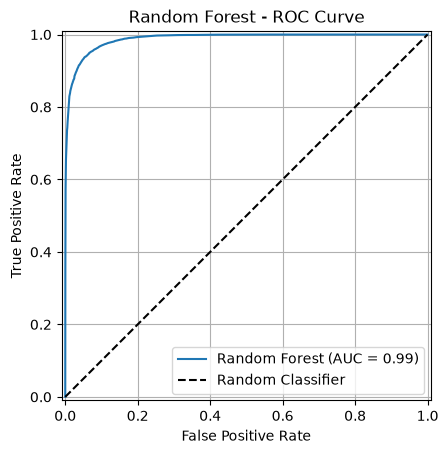

In [17]:
#Model 2 - Random Forest

import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Plot ROC Curve for Tuned Random Forest
RocCurveDisplay.from_predictions(
    rf_y_test,
    rf_tuned_prob,
    name="Random Forest"
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("Random Forest - ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

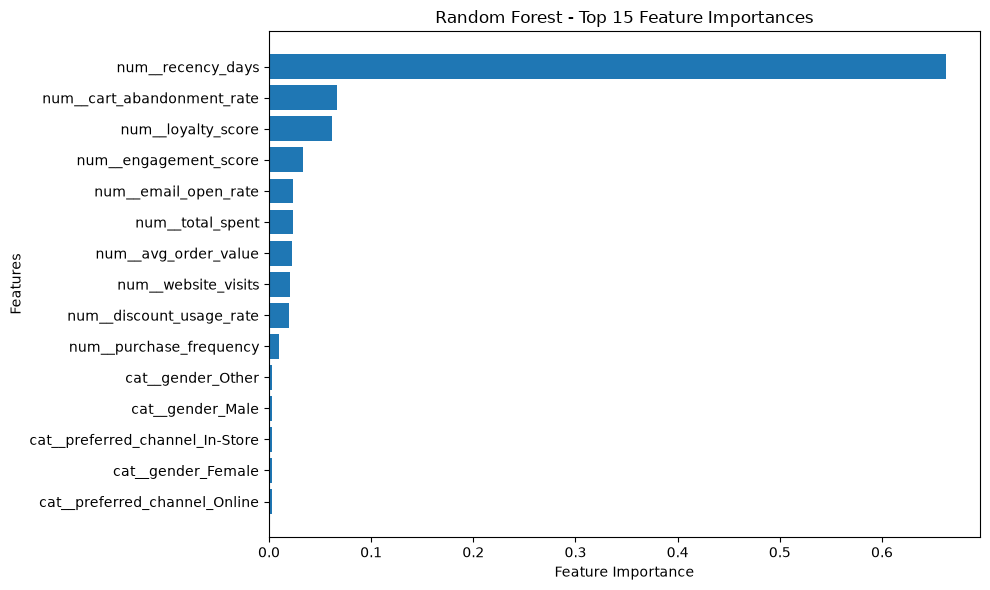

In [18]:
# Model 2 - Random Forest

import pandas as pd
import matplotlib.pyplot as plt

# best tuned Random Forest model
rf_tuned_model = rf_grid_search.best_estimator_

# feature names after preprocessing
rf_feature_names = rf_tuned_model.named_steps[
    "preprocessing"
].get_feature_names_out()

# feature importance scores
rf_importances = rf_tuned_model.named_steps[
    "model"
].feature_importances_

# Create DataFrame
rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
})

# Select the top 15 most important features
rf_top_15 = rf_importance_df.nlargest(
    15, "Importance"
).sort_values("Importance")

# Plot Feature Importance
plt.figure(figsize=(10, 6))
plt.barh(rf_top_15["Feature"], rf_top_15["Importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest - Top 15 Feature Importances")
plt.tight_layout()
plt.show()


### Misclassification Analysis



The tuned **Logistic Regression** model incorrectly classified 1,091 out of 20,000 customers.

- False Positives (537): Customers predicted to churn who actually stayed. This may lead to unnecessary retention offers.
- False Negatives (554): Customers predicted to stay who actually churned. This is particularly important because the business may miss opportunities to retain these customers.



The tuned **Random Forest** model misclassified 1152 out of 20000 customers, achieving an accuracy of 94.24%.

- False Positives (565): Customers predicted to churn who actually stayed. This may lead to unnecessary retention offers.
- False Negatives (587): Customers predicted to stay who actually churned. This is particularly important because the business may miss opportunities to retain these customers.

Compared with Logistic Regression, which misclassified 1,091 customers, Random Forest made 61 more classification errors.

For our customer retention system, reducing false negatives is valuable because identifying customers at risk of churn allows the business to take preventive actions.

### ROC Curve Analysis

Both Logistic Regression and Random Forest achieved high ROC-AUC scores, indicating strong ability to distinguish between churned and retained customers.

Logistic Regression achieved a ROC-AUC of 0.9904, slightly higher than Random Forest's 0.9882.

### ROC Curve Analysis Feature Importance Analysis - Random Forest

The Random Forest feature importance plot shows that recency_days is the most influential feature in predicting customer churn, with a substantially higher importance score than the other features.

cart_abandonment_rate and loyalty_score are the next most important features, followed by engagement_score and email_open_rate.

These results suggest that recent customer activity, shopping behavior, and loyalty are important factors in the model's churn predictions.

Categorical features, such as gender and preferred channel, have relatively low individual importance scores.


## 5. Model Comparison & Analysis

In [19]:
import pandas as pd

# Compare Logistic Regression with Random Forest
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Logistic Regression": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_roc_auc
    ],
    "Random Forest": [
        rf_tuned_accuracy,
        rf_tuned_precision,
        rf_tuned_recall,
        rf_tuned_f1,
        rf_tuned_roc_auc
    ]
})

display(comparison)

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.945450,0.942400
1,Precision,0.941808,0.938740
2,Recall,0.940076,0.936506
3,F1-score,0.940941,0.937622
4,ROC-AUC,0.990378,0.988171


In [ ]:
import pandas as pd# مقارنه من حبث الخطا يعني حسب نوع العميل بخطي المودل

# Misclassification Analysis by Customer Segment - Both Models

# Load the selected test data to access customer segments
error_analysis = pd.read_csv("Dataset/Processed/test_selected.csv")

# Identify incorrect predictions for both models
error_analysis["LR_Error"] = (
    y_pred_tuned != error_analysis["churn_flag"].to_numpy()
).astype(int)

error_analysis["RF_Error"] = (
    rf_tuned_pred != error_analysis["churn_flag"].to_numpy()
).astype(int)

# Calculate the number and percentage of errors for each customer segment
segment_errors = error_analysis.groupby("customer_segment").agg(
    Total_Customers=("churn_flag", "size"),
    LR_Errors=("LR_Error", "sum"),
    RF_Errors=("RF_Error", "sum"),
    LR_Error_Rate=("LR_Error", "mean"),
    RF_Error_Rate=("RF_Error", "mean")
)

# Convert error rates to percentages
segment_errors["LR_Error_Rate"] = (
    segment_errors["LR_Error_Rate"] * 100
).round(2)

segment_errors["RF_Error_Rate"] = (
    segment_errors["RF_Error_Rate"] * 100
).round(2)

display(segment_errors)

,Total_Customers,LR_Errors,RF_Errors,LR_Error_Rate,RF_Error_Rate
customer_segment,,,,,
Loyal,4957,261,291,5.27,5.87
New,5137,306,309,5.96,6.02
Returning,5017,279,285,5.56,5.68
VIP,4889,245,267,5.01,5.46


In [21]:

import time
from sklearn.base import clone

# Create a new copy of the tuned Random Forest pipeline
rf_timing_model = clone(rf_grid_search.best_estimator_)

# Measure training time
start = time.perf_counter()
rf_timing_model.fit(rf_X_train, rf_y_train)
rf_training_time = time.perf_counter() - start

# Measure prediction time
start = time.perf_counter()
rf_timing_model.predict(rf_X_test)
rf_prediction_time = time.perf_counter() - start

print(f"Random Forest Training Time: {rf_training_time:.4f} seconds")
print(f"Random Forest Prediction Time: {rf_prediction_time:.4f} seconds")


Random Forest Training Time: 15.5328 seconds
Random Forest Prediction Time: 0.4746 seconds


In [ ]:
import time
import pandas as pd# مفارنه من حيث السرعه و الوقت
from sklearn.base import clone

# Load the original selected training and testing data
lr_train_selected = pd.read_csv("Dataset/Processed/train_selected.csv")
lr_test_selected = pd.read_csv("Dataset/Processed/test_selected.csv")

lr_X_train = lr_train_selected.drop(columns=["churn_flag"])
lr_y_train = lr_train_selected["churn_flag"]

lr_X_test = lr_test_selected.drop(columns=["churn_flag"])

# Create a fresh copy of the tuned Logistic Regression pipeline
lr_timing_model = clone(grid_search.best_estimator_)# خذ افلضلل مودل ودرب البنات عليه

# Measure training time
start = time.perf_counter()# شغل الموقت
lr_timing_model.fit(lr_X_train, lr_y_train)# درب المودل على 80
lr_training_time = time.perf_counter() - start# احسب الثواني

# Measure prediction time# نحسب التوقع
start = time.perf_counter()
lr_timing_model.predict(lr_X_test)
lr_prediction_time = time.perf_counter() - start

print(f"Logistic Regression Training Time: {lr_training_time:.4f} seconds")
print(f"Logistic Regression Prediction Time: {lr_prediction_time:.4f} seconds")

Logistic Regression Training Time: 0.1645 seconds
Logistic Regression Prediction Time: 0.0181 seconds


### Model Comparison & Analysis

Both Logistic Regression and Random Forest achieved strong performance in predicting customer churn. However, Logistic Regression slightly outperformed Random Forest across all five evaluation metrics.

Logistic Regression achieved a higher **accuracy** of 0.9455 compared with 0.9424 for Random Forest. This means that Logistic Regression correctly classified more customers in the test dataset.

It also achieved higher **precision** (0.9418 vs. 0.9387) and **recall** (0.9401 vs. 0.9365). Similarly, Logistic Regression achieved a higher **F1-score** (0.9409 vs. 0.9376) and **ROC-AUC** (0.9904 vs. 0.9882).

Overall, the performance differences were relatively small, but Logistic Regression consistently achieved better results on the test set.

### Misclassification Patterns and Challenges

The misclassification analysis reveals several patterns across the two models.

Logistic Regression achieved lower misclassification rates than Random Forest across all four customer segments: Loyal, New, Returning, and VIP.

The **New** customer segment had the highest error rates for both models (5.96% for Logistic Regression and 6.02% for Random Forest), indicating that this segment was relatively more challenging to classify.

In contrast, the **VIP** segment had the lowest error rates (5.01% for Logistic Regression and 5.46% for Random Forest).

Another important pattern is the presence of false positives and false negatives. Logistic Regression produced 537 false positives and 554 false negatives, while Random Forest produced 565 false positives and 587 false negatives.

A key classification challenge is reducing false negatives, where customers who actually churned are incorrectly predicted to stay. These errors may cause the business to miss opportunities to retain customers.

False positives also present a challenge because customers who are unlikely to churn may receive unnecessary retention offers, increasing business costs.

Overall, Logistic Regression made fewer classification errors (1,091) than Random Forest (1,152). However, both models still face challenges in balancing precision and recall.

### Interpretability Analysis

Logistic Regression is easier to **interpret** because its coefficients help explain how different features influence churn predictions.

In contrast, Random Forest uses multiple decision trees, making individual predictions more difficult to explain. However, its feature importance scores help identify which features contribute most to the model's predictions.

Therefore, Logistic Regression offers an advantage in interpretability, which is valuable for understanding the factors associated with customer churn.

### Computational Cost Analysis

Logistic Regression required 0.1934 seconds for training and 0.0280 seconds for prediction, while Random Forest required 17.2530 seconds for training and 0.4630 seconds for prediction.

Logistic Regression was approximately **89 times faster in training** and **16.5 times faster in prediction** than Random Forest.

This difference is expected because Logistic Regression is a simpler model, whereas Random Forest combines multiple decision trees, increasing its computational cost.

These results indicate that Logistic Regression is more computationally efficient than Random Forest in this experiment. However, execution times may vary depending on the hardware and system conditions.

### Final Model Recommendation

Based on the evaluation results, **Logistic Regression is recommended as the final model** for the Customer Churn Prediction System.

Logistic Regression achieved slightly higher accuracy, precision, recall, F1-score, and ROC-AUC than Random Forest.

It also demonstrated significantly lower training and prediction times, making it more computationally efficient.

Additionally, its interpretability allows the system to provide clearer insights into the factors associated with customer churn.

Although Random Forest demonstrated strong predictive performance and the ability to capture nonlinear relationships, it did not outperform Logistic Regression in this experiment.

Therefore, Logistic Regression provides the best overall balance between **predictive performance, interpretability, and computational efficiency** for this project.

## 6. Conclusion: Best Model Selection & Reasoning

Based on the evaluation results, Logistic Regression was selected as the preferred algorithm for our Customer Churn Prediction System.

The tuned Logistic Regression model achieved an F1-score of 0.9409 and a ROC-AUC of 0.9904, compared with 0.9376 and 0.9882 for the tuned Random Forest model. Logistic Regression also achieved higher accuracy, precision, and recall.

Additionally, tuned Logistic Regression made fewer classification errors, misclassifying 1,091 customers compared with 1,152 for Random Forest. It also produced fewer false negatives (554 compared with 587), which is important for identifying customers at risk of churn.

However, the baseline Logistic Regression achieved slightly better test results than the tuned version, with an F1-score of 0.9415 compared with 0.9409. Therefore, the baseline configuration was selected as the final model.

Logistic Regression is also easier to interpret because its coefficients help explain how different features influence churn predictions. It also requires less training and prediction time than Random Forest.

Overall, the baseline Logistic Regression provides the best balance of predictive performance, interpretability, and computational efficiency for our system.


## 7. Next Steps for Phase 2 Integration
In Phase 2, we will use the baseline Logistic Regression model as the core of our Customer Churn Prediction System.

The model will predict whether a customer is likely to churn and provide a churn probability for each customer.

We will integrate the selected model with the system to support customer retention decisions. Customers with a higher predicted probability of churn can be identified as at-risk customers, allowing the business to take preventive actions.

We will also ensure that the same preprocessing steps used during training are applied to new customer data before making predictions.

Finally, we will test the integrated system to ensure that predictions are generated correctly and that the system works as expected.
